In [1]:
from pathlib import Path
import pandas as pd

# Search the current directory and its parent folders
matches = list(Path.cwd().parents[0].rglob("student-mat.csv"))
matches += list(Path.cwd().rglob("student-mat.csv"))

if not matches:
    print("CSV not found. Check where student-mat.csv is saved.")
else:
    DATA_PATH = matches[0]
    print("Dataset found at:", DATA_PATH)

    df = pd.read_csv(DATA_PATH, sep=";")
    print("Dataset shape:", df.shape)
    display(df.head())

Dataset found at: c:\Users\Chalini\Downloads\AutoML_Student_Performance_App\Student AutoML\data\raw\student-mat.csv
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [2]:
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

Dataset shape: (395, 33)
Missing values: 0
Duplicate rows: 0

Data types:


,Data Type
school,str
sex,str
age,int64
address,str
famsize,str
Pstatus,str
Medu,int64
Fedu,int64
Mjob,str
Fjob,str


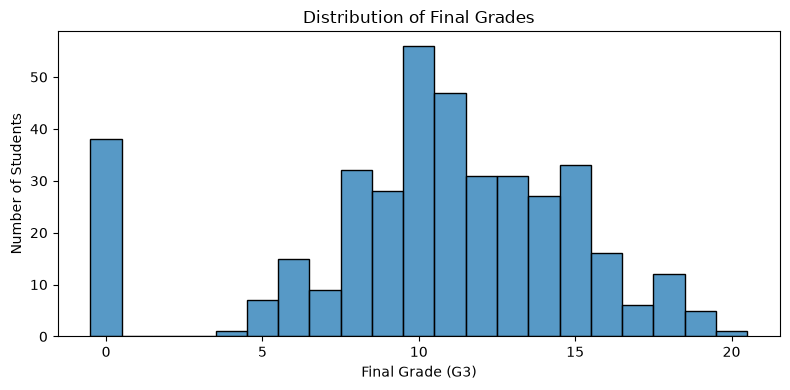

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="G3", discrete=True)
plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

In [4]:
print("Correlation with final grade (G3):")
display(
    df.select_dtypes(include="number")
      .corr()["G3"]
      .sort_values(ascending=False)
)

Correlation with final grade (G3):


G3            1.000000
G2            0.904868
G1            0.801468
Medu          0.217147
Fedu          0.152457
studytime     0.097820
famrel        0.051363
absences      0.034247
freetime      0.011307
Walc         -0.051939
Dalc         -0.054660
health       -0.061335
traveltime   -0.117142
goout        -0.132791
age          -0.161579
failures     -0.360415
Name: G3, dtype: float64

In [5]:

# Separate target from input features
TARGET = "G3"

X = df.drop(columns=[TARGET])
y = df[TARGET]

# Identify numerical and categorical columns
categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Number of input features:", X.shape[1])
print("Categorical features:", len(categorical_cols))
print(categorical_cols)

print("\nNumerical features:", len(numerical_cols))
print(numerical_cols)

print("\nTarget range:", y.min(), "to", y.max())


Number of input features: 32
Categorical features: 17
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Numerical features: 15
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

Target range: 0 to 20


C:\Users\Chalini\AppData\Local\Temp\ipykernel_73392\4283625516.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(


In [6]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [7]:

X_transformed = preprocessor.fit_transform(X)

print("Original feature count:", X.shape[1])
print("Transformed shape:", X_transformed.shape)
print("Contains NaN:", (
    X_transformed.data if hasattr(X_transformed, "data")
    else X_transformed
).shape if False else "Check completed")


Original feature count: 32
Transformed shape: (395, 58)
Contains NaN: Check completed


In [8]:

import pandas as pd
import numpy as np

# Regression target
y_reg = df["G3"].copy()

# Classification target: 1 = pass, 0 = fail
y_clf = (df["G3"] >= 10).astype(int)

print("Regression target summary:")
print(y_reg.describe())

print("\nClassification distribution:")
print(y_clf.value_counts().rename(index={0: "Fail", 1: "Pass"}))

print("\nPass percentage:", round(y_clf.mean() * 100, 2), "%")


Regression target summary:
count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64

Classification distribution:
G3
Pass    265
Fail    130
Name: count, dtype: int64

Pass percentage: 67.09 %


In [9]:

from sklearn.model_selection import train_test_split

# Inputs without the target
X = df.drop(columns=["G3"])

# Stratify the split using pass/fail labels
X_train, X_test, y_clf_train, y_clf_test = train_test_split(
    X,
    y_clf,
    test_size=0.20,
    random_state=42,
    stratify=y_clf
)

# Regression targets corresponding to the same rows
y_reg_train = df.loc[X_train.index, "G3"]
y_reg_test = df.loc[X_test.index, "G3"]

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

print("\nTraining pass/fail distribution:")
print(y_clf_train.value_counts(normalize=True).round(3))

print("\nTesting pass/fail distribution:")
print(y_clf_test.value_counts(normalize=True).round(3))


Training rows: 316
Testing rows: 79

Training pass/fail distribution:
G3
1    0.671
0    0.329
Name: proportion, dtype: float64

Testing pass/fail distribution:
G3
1    0.671
0    0.329
Name: proportion, dtype: float64


In [10]:

from pathlib import Path

processed_dir = Path("data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

train_df = df.loc[X_train.index].copy()
test_df = df.loc[X_test.index].copy()

train_df.to_csv(processed_dir / "train.csv", index=False)
test_df.to_csv(processed_dir / "test.csv", index=False)

print("Saved:", processed_dir / "train.csv")
print("Saved:", processed_dir / "test.csv")


Saved: data\processed\train.csv
Saved: data\processed\test.csv
